# DLM tutorial: the dlmmc package API

This notebook prepares an ozone time series and regressors, fits a DLM with `dlmmc.fit()`, and explores the returned xarray posterior. It uses the vanilla AR1 model and example data included in this repository.

Install the package and dependencies by following `INSTALL.md`. Stan sources ship inside the package and compile lazily on the first fit. To compile every supported model ahead of time, run `python compile_stan_models.py` from the repository root.

## Import the required packages

In [ ]:
# Import required modules
import arviz as az
import dlmmc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import xarray as xr
%matplotlib inline

/Users/sdavis/miniconda3/envs/dlmmc-cmdstanpy2/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Choose a DLM model

The package includes `vanilla_ar1`, `vanilla_ar2`, `noregs_ar1`, `dynregs_ar1`, and no-seasonal variants. This tutorial uses `vanilla_ar1`, which includes a nonlinear trend, seasonal cycle, static regression coefficients, and an AR1 process. See `models/model_descriptions/` for details.

In [ ]:
model_name = 'vanilla_ar1'

# Load the example time series

This example uses the BASIC stratospheric ozone composite [Ball et al. 2017](https://www.research-collection.ethz.ch/handle/20.500.11850/202027) and selects one pressure/latitude series. The dataset is opened with xarray so variables can be selected by their named dimensions.

For your own data, prepare `d` as a one-dimensional time series and `s` as its one-dimensional measurement-uncertainty series. Pass both directly to `dlmmc.fit()`. The package handles missing observations and corresponding uncertainties internally.

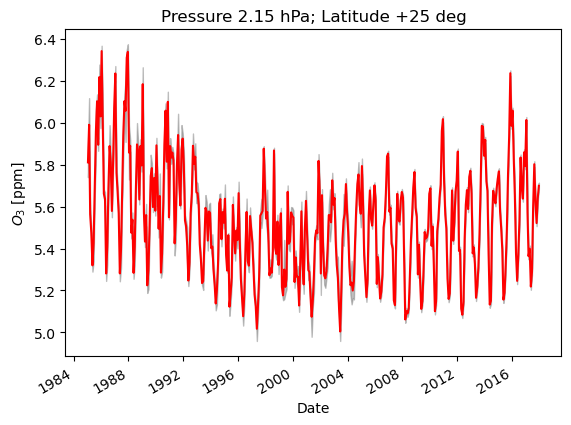

In [ ]:
# Open the example dataset and decode its IDL Julian-day coordinate once
source_ds = xr.open_dataset('data/BASIC_V1_2017_lotus_seascyc_gcsw2017_fac2.nc')
source_ds = source_ds.assign_coords(
    time=pd.to_datetime(source_ds['time'].values, unit='D', origin='julian')
)
time = source_ds['time']
P = source_ds['pressure'].to_numpy()
L = source_ds['latitude'].to_numpy()

# Select one pressure and latitude index
pressure = 22
latitude = 8

d = source_ds['o3'].isel(pressure=pressure, latitude=latitude).to_numpy()
s = source_ds['o3_sigma'].isel(pressure=pressure, latitude=latitude).to_numpy()

# Plot the selected time series and uncertainties on calendar dates
plt.title(f'Pressure {P[pressure]:.2f} hPa; Latitude {L[latitude]:+.0f} deg')
plt.plot(time, d, color='red')
plt.fill_between(time, d - s, d + s, color='grey', alpha=0.5)
plt.xlabel('Date')
plt.ylabel(r'$O_3$ [ppm]')
plt.gcf().autofmt_xdate()
plt.show()

## Prepare the regressors

The `regressors/` directory contains example indices for ENSO, solar activity, QBO30, QBO50, and stratospheric aerosol optical depth (SAOD). Both the dataset and regressor files store time as IDL Julian-day values. The data-loading cell decodes the dataset coordinate to calendar timestamps; the next cell decodes each regressor's time column the same way and uses xarray interpolation to align it with `time`.

Regressors must be finite and should be scaled comparably. Normalize them as appropriate for your analysis; missing values are not supported by the Stan model.

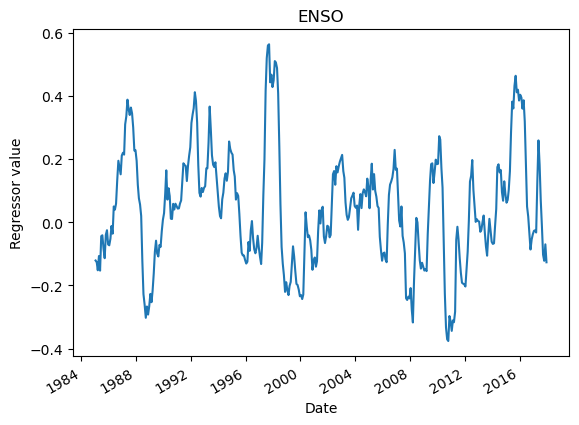

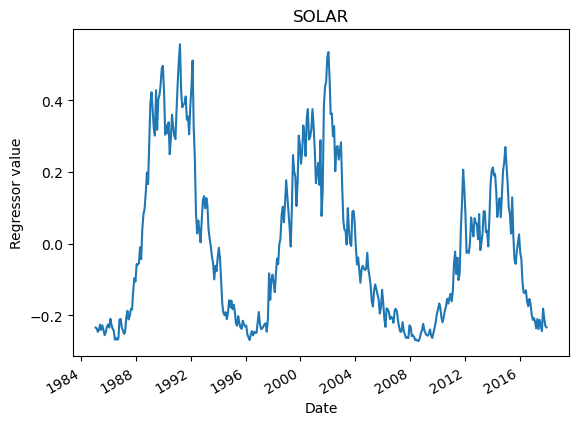

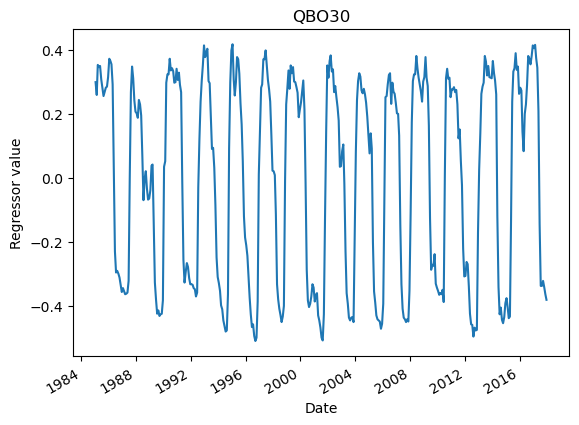

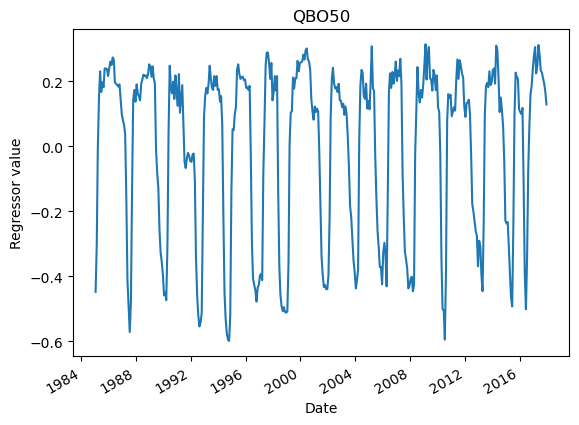

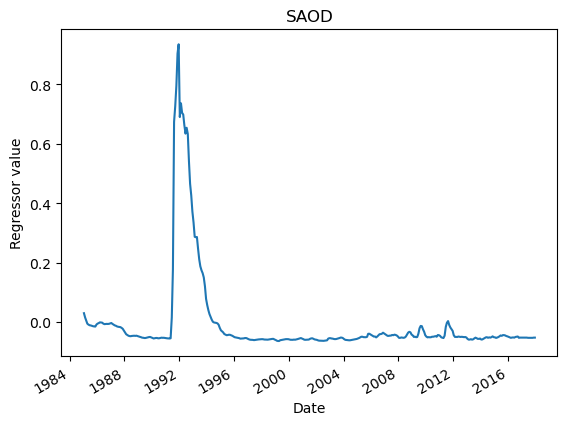

In [4]:
# Decode each IDL Julian time column and interpolate with xarray onto the data dates
def interpolate_regressor(path, column):
    values = np.loadtxt(path)
    regressor_time = pd.to_datetime(values[:, 0], unit='D', origin='julian')
    regressor = xr.DataArray(
        values[:, column],
        coords={'time': regressor_time},
        dims=('time',),
    )
    return regressor.interp(time=time).to_numpy()

enso = interpolate_regressor('regressors/ENSO_MEI_1950_201802.txt', 1)
solar = interpolate_regressor('regressors/Flux_F30_monthly_195111_201803_absolute.txt', 1)
qbo30 = interpolate_regressor('regressors/multi_qbo30_1953_2018.txt', 1)
qbo50 = interpolate_regressor('regressors/multi_qbo50_1953_2018.txt', 1)
saod = interpolate_regressor('regressors/sad_1979_2017_10deg_60S_60N.txt', latitude + 1)

regressor_names = ['ENSO', 'SOLAR', 'QBO30', 'QBO50', 'SAOD']
regressors = np.column_stack([enso, solar, qbo30, qbo50, saod])

for name, values in zip(regressor_names, (enso, solar, qbo30, qbo50, saod)):
    plt.plot(time, values)
    plt.title(name)
    plt.xlabel('Date')
    plt.ylabel('Regressor value')
    plt.gcf().autofmt_xdate()
    plt.show()

## Set prior options

`dlmmc.fit()` uses package defaults unless you override them. Supply individual prior values as keyword arguments or several values in a `priors` dictionary. Prior scales use the normalized units expected by the Stan models. Optional per-chain `inits` are starting values, not chain-specific priors.

In [ ]:
# Override only priors that differ from the package defaults
priors = {
    'S': 10.0,
    'sigma_trend_prior': 1e-4,
    'sigma_seas_prior': 0.01,
    'sigma_AR_prior': 0.5,
}

## Fit the model

`dlmmc.fit()` accepts the xarray time series, uncertainty, and regressors, and returns a labeled xarray Dataset with `chain`, `draw`, `time`, and `regressor` dimensions. `samples` is the number of retained draws per chain; warmup draws are excluded.

This example runs four chains with 1,000 warmup and 2,000 sampling iterations per chain. Shorten these values while exploring, then choose settings based on sampler diagnostics.

In [ ]:
# Create labeled regressor inputs and fit with the package API
regressors_da = xr.DataArray(
    regressors,
    dims=('time', 'regressor'),
    coords={'time': time, 'regressor': regressor_names},
)
data_series = source_ds['o3'].isel(pressure=pressure, latitude=latitude)
uncertainty = source_ds['o3_sigma'].isel(pressure=pressure, latitude=latitude)

chains = 4
warmup = 1000
sampling = 2000
inits = None  # Or supply one initialization mapping per chain.

fit = dlmmc.fit(
    data=data_series,
    uncertainty=uncertainty,
    regressors=regressors_da,
    model=model_name,
    priors=priors,
    chains=chains,
    warmup=warmup,
    samples=sampling,
    seed=42,
    inits=inits,
)

14:25:33 - cmdstanpy - INFO - CmdStan start processing
chain 1:   0%|          | 0/3000 [00:00<?, ?it/s, (Warmup)]



chain 1:   0%|          | 1/3000 [00:00<08:06,  6.17it/s, (Warmup)]

chain 1:   3%|▎         | 100/3000 [00:08<04:07, 11.74it/s, (Warmup)]


chain 1:   7%|▋         | 200/3000 [00:12<02:48, 16.64it/s, (Warmup)]





chain 1:  10%|█         | 300/3000 [00:19<02:49, 15.95it/s, (Warmup)]




chain 1:  13%|█▎        | 400/3000 [00:24<02:31, 17.11it/s, (Warmup)]



chain 1:  17%|█▋        | 500/3000 [00:28<02:10, 19.19it/s, (Warmup)]


chain 1:  20%|██        | 600/3000 [00:32<01:51, 21.54it/s, (Warmup)]



chain 1:  23%|██▎       | 700/3000 [00:35<01:33, 24.55it/s, (Warmup)]

chain 1:  27%|██▋       | 800/3000 [00:37<01:18, 27.87it/s, (Warmup)]





chain 1:  33%|███▎      | 1000/3000 [00:43<01:06, 30.21it/s, (Sampling)]


chain 1:  37%|███▋      | 1100/3000 [00:52<01:32, 20.52it/s, (Sampling)]


chain 1:  40%|████      | 1200/3000 [01:00<01:46, 16.83it/s, (Sampling)]


cha


14:29:16 - cmdstanpy - INFO - CmdStan done processing.
14:29:16 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_vanilla_ar1_cmdstanpy.stan', line 178, column 8 to column 54)
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_vanilla_ar1_cmdstanpy.stan', line 178, column 8 to column 54)
Consider re-running with show_console=True if the above output is unclear!


## Inspect posterior draws

The fit result is already an xarray Dataset. It preserves chain and draw coordinates and labels outputs with the input time and regressor coordinates. Use xarray selections and reductions to summarize results; flatten chain/draw only when a plotting helper requires a single sample axis.

In [ ]:
# Keep posterior as xarray; flatten only for existing histogram helpers
posterior = fit
trend = posterior['trend'].values.reshape(-1, len(time))
slope = posterior['slope'].values.reshape(-1, len(time))
seasonal_cycle = posterior['seasonal'].values.reshape(-1, len(time))
regressor_coefficients = posterior['beta'].values.reshape(-1, len(regressor_names))
sigma_trend = posterior['sigma_trend'].values.reshape(-1)
sigma_seas = posterior['sigma_seas'].values.reshape(-1)
sigma_AR = posterior['sigma_AR'].values.reshape(-1)
rhoAR1 = posterior['rhoAR1'].values.reshape(-1)

## Finally, let's make some plots of the outputs!

**Obviously we can compute and plot whatever we like now we have the results, but let's make a few example plots of the various parameters we have inferred to showcase the results.**

### Let's start by plotting the recovered dlm trend and corresponding (1$\sigma$) uncertainties:

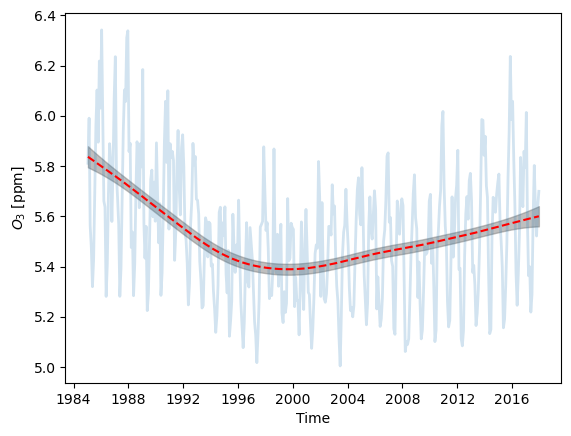

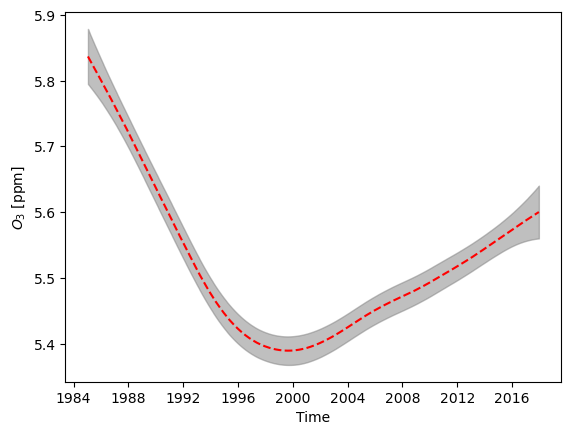

In [9]:
# Plot posterior trend summaries against the data
trend_mean = np.mean(trend, axis=0)
trend_std = np.std(trend, axis=0)

plt.plot(time, d, lw=2, alpha=0.2)
plt.plot(time, trend_mean, color='red', ls='--')
plt.fill_between(time, trend_mean - trend_std, trend_mean + trend_std, color='grey', alpha=0.5)
plt.xlabel('Time')
plt.ylabel(r'$O_3$ [ppm]')
plt.show()

# Same plot without the observations for a closer look at the trend
plt.plot(time, trend_mean, color='red', ls='--')
plt.fill_between(time, trend_mean - trend_std, trend_mean + trend_std, color='grey', alpha=0.5)
plt.xlabel('Time')
plt.ylabel(r'$O_3$ [ppm]')
plt.show()

### We can also plot the recovered slope of the trend as a function of time (negative slope indicates ozone depletion, positive slope indicates recovery):

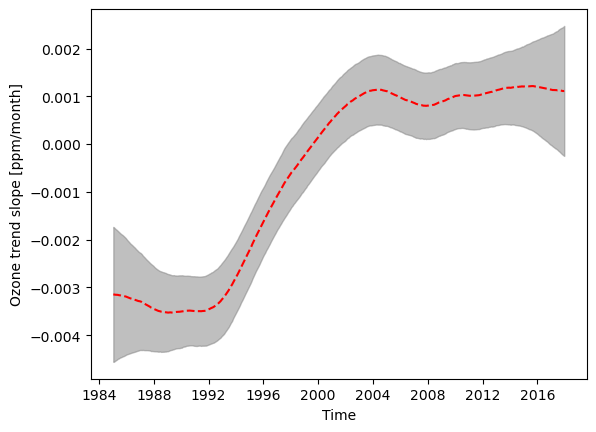

In [10]:
# Plot the posterior slope of the recovered trend
slope_mean = np.mean(slope, axis=0)
slope_std = np.std(slope, axis=0)
plt.plot(time, slope_mean, color='red', ls='--')
plt.fill_between(time, slope_mean - slope_std, slope_mean + slope_std, color='grey', alpha=0.5)
plt.xlabel('Time')
plt.ylabel('Ozone trend slope [ppm/month]')
plt.show()

### Now for the recovered seasonal cycle - note that modulation in the amplitude of the seasonal cycle is allowed in the dlm model (and here is preferred by the data):

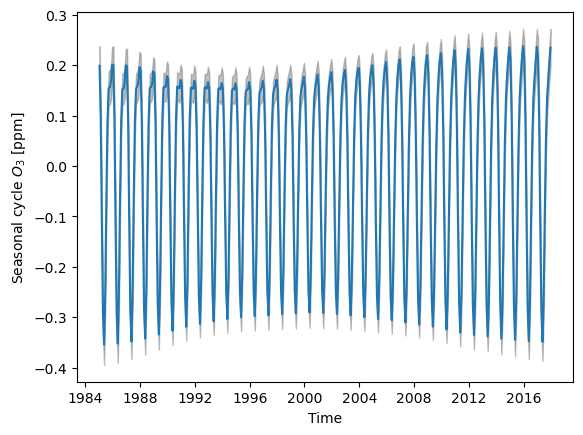

In [11]:
# Plot the posterior seasonal cycle and uncertainty
seasonal_mean = np.mean(seasonal_cycle, axis=0)
seasonal_std = np.std(seasonal_cycle, axis=0)
plt.plot(time, seasonal_mean)
plt.fill_between(time, seasonal_mean - seasonal_std, seasonal_mean + seasonal_std, color='grey', alpha=0.5)
plt.xlabel('Time')
plt.ylabel('Seasonal cycle $O_3$ [ppm]')
plt.show()

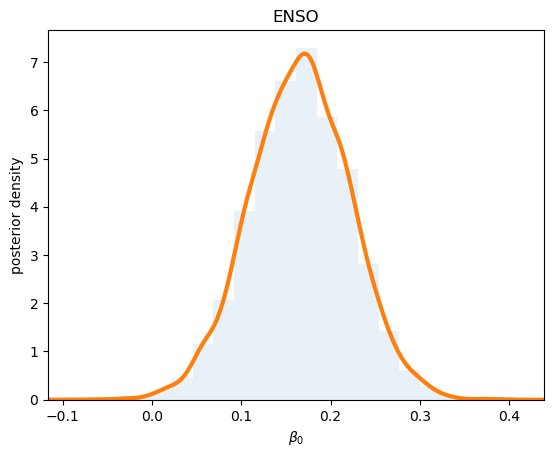

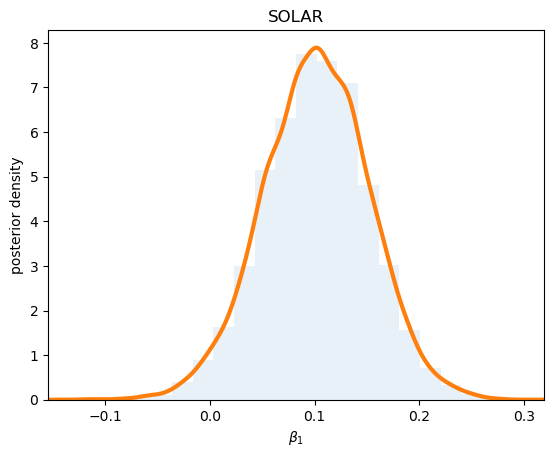

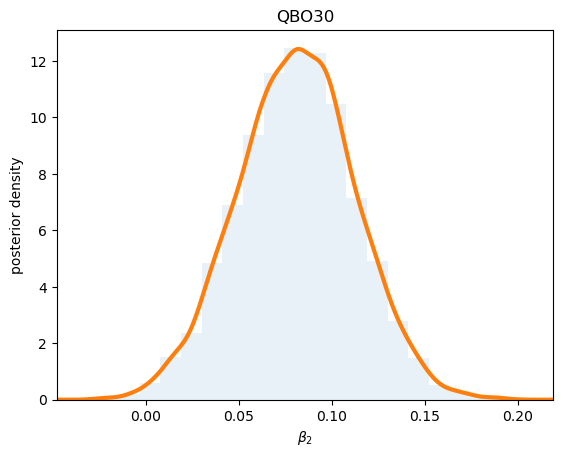

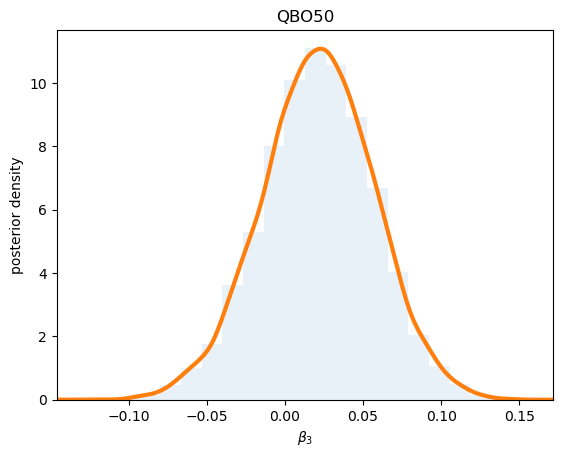

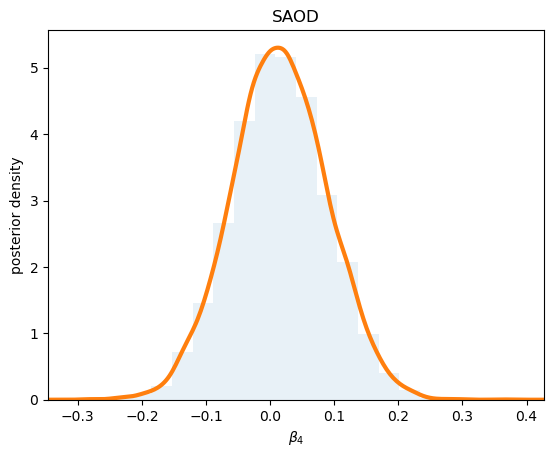

In [12]:
# Plot posteriors for the regression coefficients
regressor_names = ['ENSO', 'SOLAR', 'QBO30', 'QBO50', 'SAOD']
for i in range(len(regressors.T)):
    beta = regressor_coefficients[:,i]
    kde = stats.gaussian_kde(beta)
    x = np.linspace(min(beta) - np.ptp(beta)*0.1, max(beta) + np.ptp(beta)*0.1, 300)
    plt.hist(beta, bins=20, density=True, alpha = 0.1)
    plt.plot(x, kde(x), lw = 3)
    plt.xlim(x[0], x[-1])
    plt.title(regressor_names[i])
    plt.ylabel('posterior density')
    plt.xlabel(r'$\beta_{}$'.format(i))
    plt.show()

### We can also plot histograms of the dlm hyper-parameter posteriors:

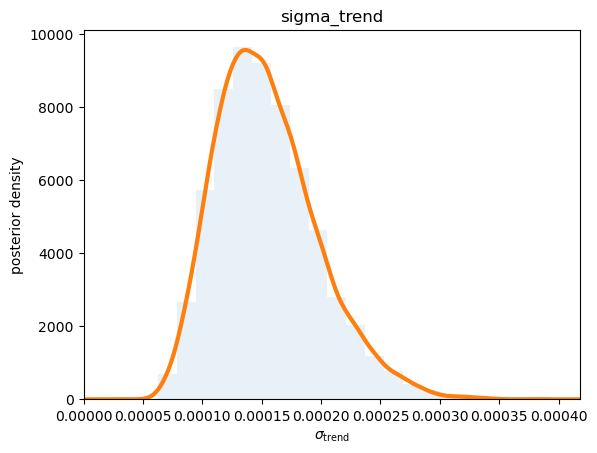

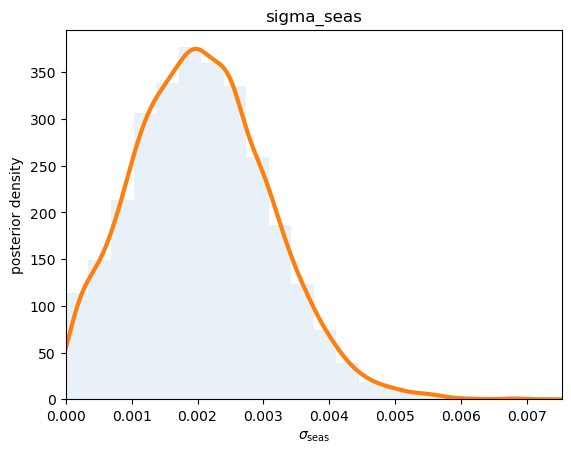

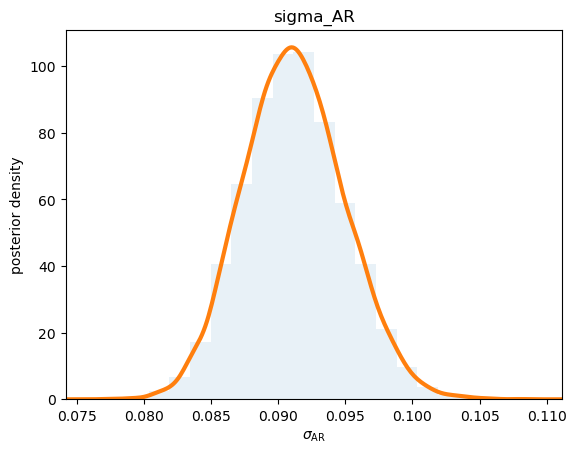

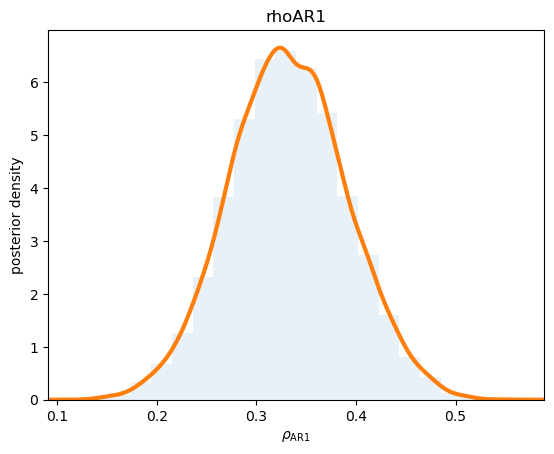

In [13]:
# Plot posteriors for the DLM hyper parameters
kde = stats.gaussian_kde(sigma_trend)
x = np.linspace(0, max(sigma_trend)*1.1, 300)
plt.hist(sigma_trend, bins=20, density=True, alpha = 0.1)
plt.plot(x, kde(x), lw = 3)
plt.xlim(x[0], x[-1])
plt.title('sigma_trend')
plt.ylabel('posterior density')
plt.xlabel(r'$\sigma_\mathrm{trend}$')
plt.show()

kde = stats.gaussian_kde(sigma_seas)
x = np.linspace(0, max(sigma_seas)*1.1, 300)
plt.hist(sigma_seas, bins=20, density=True, alpha = 0.1)
plt.plot(x, kde(x), lw = 3)
plt.xlim(x[0], x[-1])
plt.title('sigma_seas')
plt.ylabel('posterior density')
plt.xlabel(r'$\sigma_\mathrm{seas}$')
plt.show()

kde = stats.gaussian_kde(sigma_AR)
x = np.linspace(min(sigma_AR) - np.ptp(sigma_AR)*0.1, max(sigma_AR) + np.ptp(sigma_AR)*0.1, 300)
plt.hist(sigma_AR, bins=20, density=True, alpha = 0.1)
plt.plot(x, kde(x), lw = 3)
plt.xlim(x[0], x[-1])
plt.title('sigma_AR')
plt.ylabel('posterior density')
plt.xlabel(r'$\sigma_\mathrm{AR}$')
plt.show()

kde = stats.gaussian_kde(rhoAR1)
x = np.linspace(min(rhoAR1) - np.ptp(rhoAR1)*0.1, max(rhoAR1) + np.ptp(rhoAR1)*0.1, 300)
plt.hist(rhoAR1, bins=20, density=True, alpha = 0.1)
plt.plot(x, kde(x), lw = 3)
plt.xlim(x[0], x[-1])
plt.title('rhoAR1')
plt.ylabel('posterior density')
plt.xlabel(r'$\rho_\mathrm{AR1}$')
plt.show()

### Check the sampler traces

Trace plots show draws by chain and can reveal poor mixing or trends. They are one diagnostic, not proof of convergence. If chains mix poorly, investigate the model and data and run longer chains; also review CmdStan's summary diagnostics such as R-hat and effective sample size.

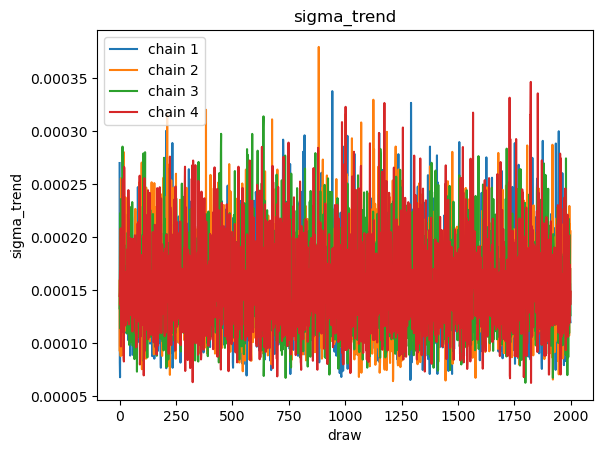

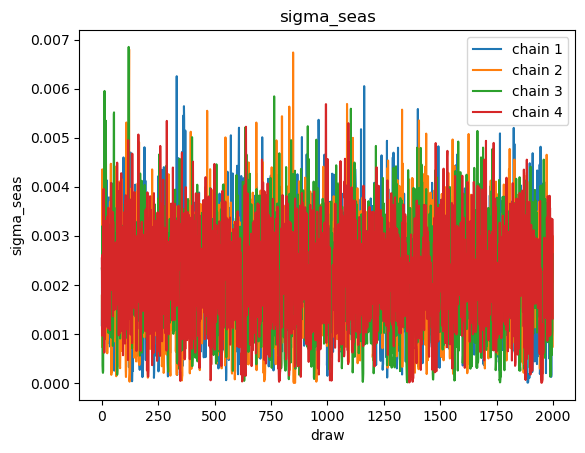

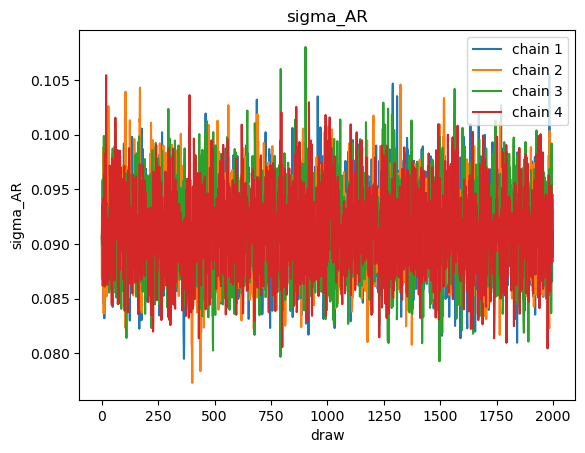

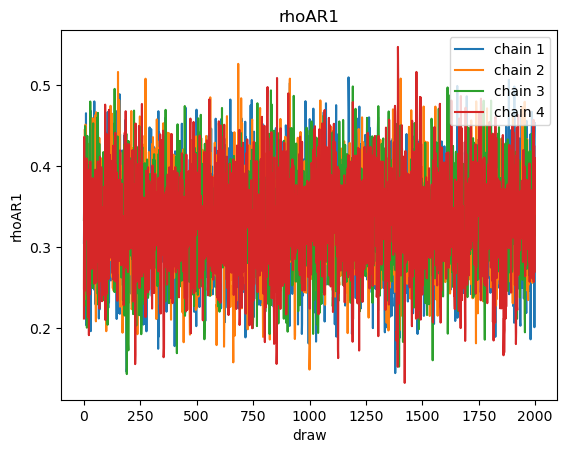

In [14]:
# Plot each chain separately for the model hyperparameters
for name in ('sigma_trend', 'sigma_seas', 'sigma_AR', 'rhoAR1'):
    for chain in posterior['chain'].values:
        values = posterior[name].sel(chain=chain)
        plt.plot(posterior['draw'].values, values.values, label=f'chain {chain}')
    plt.title(name)
    plt.xlabel('draw')
    plt.ylabel(name)
    plt.legend()
    plt.show()

### Summarize convergence diagnostics

Compare chains using R-hat and effective sample size for parameters that matter to your analysis. R-hat near 1 (commonly below 1.01) and adequate bulk/tail ESS are reassuring, but no threshold proves convergence. `dlmmc.fit()` records divergent transitions in the posterior attributes; investigate divergences or poor mixing rather than assuming longer chains alone will fix them.

In [ ]:
# Summarize selected scalar hyperparameters from the labeled posterior
diagnostic_parameters = ['sigma_trend', 'sigma_seas', 'sigma_AR', 'rhoAR1']
diagnostic_data = az.from_dict(
    data={
        'posterior': {
            name: posterior[name].transpose('chain', 'draw').to_numpy()
            for name in diagnostic_parameters
        }
    },
    sample_dims=['chain', 'draw'],
    coords={
        'chain': posterior['chain'].to_numpy(),
        'draw': posterior['draw'].to_numpy(),
    },
)
display(az.summary(diagnostic_data, var_names=diagnostic_parameters, kind='all', round_to=3))
print(f"Divergent transitions: {posterior.attrs.get('divergent_transitions', 'unavailable')}")

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
sigma_trend,0.000,0.000,0.000,0.000,7179.390,5663.968,1.000,0.000,0.000
sigma_seas,0.002,0.001,0.000,0.004,4064.968,2536.710,1.001,0.000,0.000
sigma_AR,0.091,0.004,0.085,0.097,6294.610,5394.738,1.001,0.000,0.000
rhoAR1,0.332,0.059,0.239,0.427,6360.711,5012.469,1.001,0.001,0.001


Divergent transitions: 0


### Finally, we can do things like plot the posterior for the net background change in ozone between two key dates (here, January 1998 and December 2017)

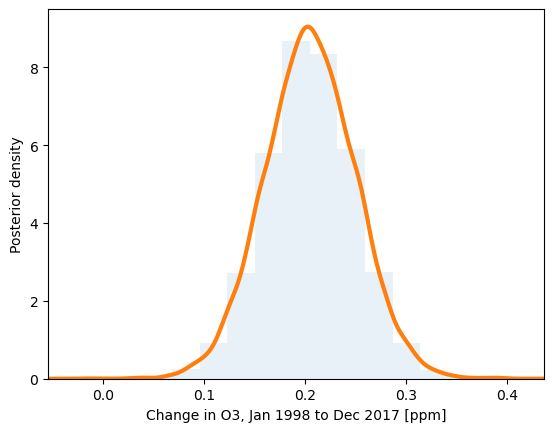

In [16]:
# Compare the trend at January 1998 and December 2017
jan1998 = 156
dec2017 = -1
delta_o3 = trend[:, dec2017] - trend[:, jan1998]

kde = stats.gaussian_kde(delta_o3)
x = np.linspace(delta_o3.min() - np.ptp(delta_o3) * 0.1, delta_o3.max() + np.ptp(delta_o3) * 0.1, 300)
plt.hist(delta_o3, bins=15, alpha=0.1, density=True)
plt.plot(x, kde(x), lw=3)
plt.xlim(x[0], x[-1])
plt.xlabel('Change in O3, Jan 1998 to Dec 2017 [ppm]')
plt.ylabel('Posterior density')
plt.show()

source_ds.close()

## Congratulations, you made it to the end of the tutorial! 

## By now you should get the idea and, I hope, be able to use this notebook as a template for performing dlm regression on your own data. Good luck and happy DLMing!